# APDS TP03 · Fine-tuning Gemma 3 for Khmer question answering

Gemma 3 4B is fine-tuned separately on the supplied banking dataset and an alternative Khmer Wikipedia QA dataset. Both adapters start from the same frozen 4-bit checkpoint and use identical training and decoding settings. LoRA trains small updates to the language layers, and PEFT saves those updates as adapters.

## 1. Environment

In [13]:
import subprocess

try:
    gpu = subprocess.check_output(
        ["nvidia-smi", "--query-gpu=name,memory.total", "--format=csv,noheader"],
        text=True,
    ).strip()
except (FileNotFoundError, subprocess.CalledProcessError):
    gpu = ""

if not gpu:
    raise RuntimeError("Select a GPU under Runtime → Change runtime type, then reconnect.")
print(gpu)

Tesla T4, 15360 MiB


In [14]:
%pip install -q "unsloth==2026.11.2" "unsloth-zoo==2026.11.3" "transformers==5.17.0" "trl==1.15.0" "sacrebleu==2.5.1" wandb

In [15]:
import os

from google.colab import userdata

WANDB_PROJECT = "apds-tp03"

try:
    wandb_key = userdata.get("WANDB_API_KEY").strip()
except (userdata.SecretNotFoundError, userdata.NotebookAccessError):
    raise RuntimeError("Set WANDB_API_KEY in Colab Secrets and enable Notebook access.") from None
if not wandb_key:
    raise RuntimeError("WANDB_API_KEY is empty.")

os.environ["WANDB_API_KEY"] = wandb_key
os.environ["WANDB_LOG_MODEL"] = "false"
os.environ["WANDB_WATCH"] = "false"
del wandb_key

import wandb

if not wandb.login(verify=True):
    raise RuntimeError("Could not authenticate with Weights & Biases.")

## 2. Datasets

`dataasilida_cleaned.csv` is the supplied banking source. Its preparation retained 303 examples and set aside 218 flagged records. The original banking splits contain **241 train / 30 validation / 32 test** examples. Prompts contain a question alone.

The alternative is a prepared 303-example subset of [sengtha/khmer-qa](https://huggingface.co/datasets/sengtha/khmer-qa/tree/3ca26dc817cae20dc4c574e7027b581ec7cb73ae), with **242 train / 30 validation / 31 test** examples. Prompts include a Khmer Wikipedia passage. Credit goes to sengtha / iAny and Khmer Wikipedia contributors under [CC BY-SA 4.0](https://creativecommons.org/licenses/by-sa/4.0/).

In [16]:
import json
from hashlib import sha256
from io import BytesIO
from pathlib import Path
from zipfile import BadZipFile, ZipFile

from google.colab import files
import pandas as pd
from IPython.display import display

DATA_BUNDLE = Path("/content/TP03_datasets.zip")
FILE_HASHES = {
    "dataasilida_cleaned.csv": "9a0bda81775b96c0640f41224634f75eaa0d8ba88ac93d8728e7ff10d083cda3",
    "banking_splits.json": "a04bf40ed3178873c0e2ff20b41b2d6ba0cb44eb1913b85c1505649c12bf16f7",
    "khmerqa_splits.json": "e7ed63110c107ec3f25d9cf6ec71d9fb374291273c9700e0fd66cd0fe02d2c78",
}
DATASETS = {
    "banking": "Original banking",
    "khmerqa": "Khmer Wikipedia QA",
}

def load_datasets(bundle_bytes):
    try:
        with ZipFile(BytesIO(bundle_bytes)) as bundle:
            members = {name: bundle.read(name) for name in FILE_HASHES}
            attribution = bundle.read("DATASET_ATTRIBUTION.md").decode("utf-8")
    except (BadZipFile, KeyError) as error:
        raise ValueError("Expected TP03_datasets.zip with the CSV and both prepared split files.") from error

    for name, expected in FILE_HASHES.items():
        if sha256(members[name]).hexdigest() != expected:
            raise ValueError(f"The dataset bundle contains an unexpected version of {name}.")

    datasets = {name: json.loads(members[f"{name}_splits.json"]) for name in DATASETS}
    return datasets, attribution

In [17]:
if DATA_BUNDLE.is_file():
    bundle_bytes = DATA_BUNDLE.read_bytes()
else:
    uploads = files.upload()
    if DATA_BUNDLE.name not in uploads:
        raise ValueError(f"Expected {DATA_BUNDLE.name}.")
    bundle_bytes = uploads[DATA_BUNDLE.name]

datasets, dataset_attribution = load_datasets(bundle_bytes)
display(pd.DataFrame.from_dict({
    DATASETS[name]: {split: len(rows) for split, rows in splits.items()}
    for name, splits in datasets.items()
}, orient="index"))

,train,validation,test
Original banking,241,30,32
Khmer Wikipedia QA,242,30,31


## 3. Model and training configuration

In [18]:
from unsloth import FastModel
from unsloth.chat_templates import get_chat_template

import gc
from tempfile import mkdtemp

import matplotlib.pyplot as plt
import torch
from datasets import Dataset
from transformers import set_seed
from trl import SFTConfig, SFTTrainer

In [19]:
MODEL_ID = "unsloth/gemma-3-4b-it-unsloth-bnb-4bit"
MAX_LENGTH = 2048
SEED = 3407
TRAINING_STEPS = 60
LEARNING_RATE = 2e-4
LORA_RANK = 8
BATCH_SIZE = 1
ACCUMULATION_STEPS = 8
EVAL_STEPS = 10
GENERATION_SETTINGS = {
    "max_new_tokens": 768,
    "do_sample": False,
    "repetition_penalty": 1.1,
    "no_repeat_ngram_size": 8,
}

if not torch.cuda.is_available():
    raise RuntimeError("CUDA GPU unavailable.")

RESULTS_DIR = Path(mkdtemp(prefix="tp03_results_", dir="/content"))


def load_base_model():
    set_seed(SEED)
    model, processor = FastModel.from_pretrained(
        model_name=MODEL_ID,
        max_seq_length=MAX_LENGTH,
        load_in_4bit=True,
        full_finetuning=False,
    )
    return model, get_chat_template(processor, chat_template="gemma-3")

## 4. Data formatting

Supervised fine-tuning uses Gemma’s chat template. The loss covers the assistant answer and end-of-turn token. The prompt and padding labels are masked.

In [20]:
END_OF_TURN = "<end_of_turn>"


def user_turn(text):
    return {"role": "user", "content": text}


def render_prompt(processor, text):
    return processor.apply_chat_template(
        [user_turn(text)], tokenize=False, add_generation_prompt=True,
    )

In [21]:
def encode_example(row, processor, tokenizer, end_token_id):
    prompt = render_prompt(processor, row["input"])
    chat = processor.apply_chat_template(
        [user_turn(row["input"]), {"role": "assistant", "content": row["output"]}],
        tokenize=False, add_generation_prompt=False,
    )
    target = row["output"] + END_OF_TURN
    start, end = len(prompt), len(prompt) + len(target)
    if not prompt.endswith("<start_of_turn>model\n") or chat[:end] != prompt + target or chat[end:].strip():
        raise ValueError("Gemma's chat template did not render the expected assistant turn.")

    encoded = tokenizer(chat, add_special_tokens=False, return_offsets_mapping=True)
    input_ids = encoded["input_ids"]
    if len(input_ids) > MAX_LENGTH:
        raise ValueError(f"A formatted example exceeds {MAX_LENGTH} tokens.")

    labels = []
    for token_id, (left, right) in zip(input_ids, encoded["offset_mapping"], strict=True):
        in_target = left < end and right > start
        if in_target and (chat[left:start].strip() or chat[end:right].strip()):
            raise ValueError("A token overlaps text outside the assistant answer.")
        labels.append(token_id if in_target else -100)

    supervised = [label for label in labels if label != -100]
    if len(supervised) < 2 or supervised[-1] != end_token_id or end_token_id == tokenizer.unk_token_id:
        raise ValueError("The answer or end-of-turn token is missing from the labels.")
    return {"input_ids": input_ids, "labels": labels}

In [22]:
def prepare_training_data(splits, processor):
    tokenizer = getattr(processor, "tokenizer", processor)
    end_token_id = tokenizer.convert_tokens_to_ids(END_OF_TURN)

    tokenized = {}
    for name in ("train", "validation"):
        rows = Dataset.from_list(splits[name])
        tokenized[name] = rows.map(
            encode_example,
            fn_kwargs={
                "processor": processor, "tokenizer": tokenizer, "end_token_id": end_token_id,
            },
            remove_columns=rows.column_names,
        )
    return tokenized

## 5. Evaluation protocol

Each held-out prompt is evaluated before and after fine-tuning. chrF measures character n-gram overlap on a 0–100 scale. Exact match uses normalized text. The banking and Wikipedia tasks differ in context and test questions, so the primary comparison is the before-to-after change within each dataset.

In [23]:
import unicodedata
from sacrebleu.metrics import CHRF
from tqdm.auto import tqdm


@torch.inference_mode()
def generate_answers(model, processor, rows, description):
    FastModel.for_inference(model)
    tokenizer = getattr(processor, "tokenizer", processor)
    end_token_id = tokenizer.convert_tokens_to_ids(END_OF_TURN)
    stop_ids = sorted({tokenizer.eos_token_id, end_token_id} - {None, tokenizer.unk_token_id})

    answers = []
    for row in tqdm(rows, desc=description):
        inputs = tokenizer(
            render_prompt(processor, row["input"]), add_special_tokens=False, return_tensors="pt",
        ).to(model.device)
        prompt_length = inputs["input_ids"].shape[1]
        budget = min(GENERATION_SETTINGS["max_new_tokens"], MAX_LENGTH - prompt_length)
        if budget <= 0:
            raise ValueError("The prompt leaves no room for an answer.")

        settings = {**GENERATION_SETTINGS, "max_new_tokens": budget}
        output = model.generate(**inputs, **settings, eos_token_id=stop_ids, pad_token_id=tokenizer.pad_token_id)
        answer_ids = output[0, prompt_length:]
        answers.append({
            "text": tokenizer.decode(answer_ids, skip_special_tokens=True).strip(),
            "hit_limit": len(answer_ids) >= budget and answer_ids[-1].item() not in stop_ids,
        })
    return answers

In [24]:
def normalize_answer(text):
    text = unicodedata.normalize("NFC", text).casefold()
    text = text.replace(r"\r\n", "\n").replace(r"\n", "\n")
    return " ".join(text.translate({0x200B: None, 0xFEFF: None}).split())


def evaluate_answers(rows, baseline, tuned):
    predictions = pd.DataFrame([
        {
            "prompt": row["input"],
            "reference": row["output"],
            "before": before["text"],
            "after": after["text"],
            "before_hit_token_limit": before["hit_limit"],
            "after_hit_token_limit": after["hit_limit"],
        }
        for row, before, after in zip(rows, baseline, tuned, strict=True)
    ])
    references = predictions["reference"].map(normalize_answer).tolist()
    scorer = CHRF()
    scores = {}
    for stage in ("before", "after"):
        answers = predictions[stage].map(normalize_answer).tolist()
        scores[stage] = {
            "chrf": scorer.corpus_score(answers, [references]).score,
            "exact_matches": sum(answer == ref for answer, ref in zip(answers, references, strict=True)),
            "token_limit_hits": int(predictions[f"{stage}_hit_token_limit"].sum()),
        }
    return predictions, scores

## 6. Fine-tuning and held-out predictions

In [25]:
def attach_lora_adapter(model):
    FastModel.for_training(model)
    return FastModel.get_peft_model(
        model,
        finetune_vision_layers=False,
        finetune_language_layers=True,
        finetune_attention_modules=True,
        finetune_mlp_modules=True,
        r=LORA_RANK,
        lora_alpha=LORA_RANK,
        lora_dropout=0,
        bias="none",
        random_state=SEED,
    )

In [26]:
def training_config(checkpoint_dir):
    return SFTConfig(
        output_dir=str(checkpoint_dir),
        dataset_kwargs={"skip_prepare_dataset": True},
        max_length=MAX_LENGTH,
        packing=False,
        per_device_train_batch_size=BATCH_SIZE,
        per_device_eval_batch_size=1,
        gradient_accumulation_steps=ACCUMULATION_STEPS,
        max_steps=TRAINING_STEPS,
        learning_rate=LEARNING_RATE,
        warmup_steps=5,
        optim="adamw_8bit",
        weight_decay=0.01,
        lr_scheduler_type="linear",
        logging_steps=1,
        eval_strategy="steps",
        eval_steps=EVAL_STEPS,
        prediction_loss_only=True,
        save_strategy="steps",
        save_steps=EVAL_STEPS,
        save_total_limit=2,
        load_best_model_at_end=True,
        metric_for_best_model="eval_loss",
        greater_is_better=False,
        report_to="wandb",
        seed=SEED,
    )

In [27]:
def verify_supervision(trainer, tokenized):
    for name, prepared in (("train", trainer.train_dataset), ("validation", trainer.eval_dataset)):
        expected = tokenized[name]
        if len(prepared) != len(expected) or any(
            (row["input_ids"], row["labels"]) != (original["input_ids"], original["labels"])
            for row, original in zip(prepared, expected)
        ):
            raise ValueError(f"The trainer changed the {name} tokens or labels.")
        examples = [min(expected, key=lambda row: len(row["input_ids"])),
                    max(expected, key=lambda row: len(row["input_ids"]))]
        batch = trainer.data_collator(examples)
        for index, row in enumerate(examples):
            active = batch["attention_mask"][index].bool()
            ids = batch["input_ids"][index]
            labels = batch["labels"][index]
            if (ids[active].tolist() != row["input_ids"] or labels[active].tolist() != row["labels"]
                    or (labels[~active] != -100).any()):
                raise ValueError(f"The collator changed the {name} tokens, labels or padding.")

In [28]:
def train_adapter(model, processor, tokenized, checkpoint_dir):
    trainer = SFTTrainer(
        model=attach_lora_adapter(model),
        processing_class=processor,
        train_dataset=tokenized["train"],
        eval_dataset=tokenized["validation"],
        args=training_config(checkpoint_dir),
    )
    verify_supervision(trainer, tokenized)
    trainer.train()
    return trainer

In [29]:
def start_tracking(name, label, splits, work):
    return wandb.init(
        project=WANDB_PROJECT,
        group=RESULTS_DIR.name,
        name=label,
        dir=str(work),
        mode="online",
        config={
            "dataset": name,
            "split_sizes": {split: len(rows) for split, rows in splits.items()},
            "split_sha256": FILE_HASHES[f"{name}_splits.json"],
            "lora_rank": LORA_RANK,
            "generation": GENERATION_SETTINGS,
        },
        save_code=False,
        settings=wandb.Settings(console="off", disable_code=True, disable_git=True),
    )

In [30]:
def log_heldout_scores(run, scores, test_count, best_validation_loss):
    run.summary.update({
        f"heldout/{stage}/{metric}": value
        for stage, metrics in scores.items()
        for metric, value in metrics.items()
    })
    run.summary["heldout/chrf_change"] = scores["after"]["chrf"] - scores["before"]["chrf"]
    run.summary["heldout/test_examples"] = test_count
    run.summary["eval/best_loss"] = best_validation_loss

In [31]:
def save_dataset_outputs(name, label, trainer, processor, predictions, run_url):
    folder = RESULTS_DIR / name
    folder.mkdir(exist_ok=True)
    trainer.save_model(str(folder / "adapter"))
    processor.save_pretrained(str(folder / "adapter"))
    predictions.to_csv(folder / "predictions.csv", index=False, encoding="utf-8-sig")
    print(label)
    print(f"Weights & Biases: {run_url}")
    with pd.option_context("display.max_colwidth", 180):
        display(predictions[["prompt", "reference", "before", "after"]].head(2))

In [32]:
def run_dataset(name):
    label = DATASETS[name]
    splits = datasets[name]
    work = Path(mkdtemp(prefix=f"tp03_{name}_", dir="/content"))
    with start_tracking(name, label, splits, work) as run:
        model, processor = load_base_model()
        tokenized = prepare_training_data(splits, processor)
        before = generate_answers(model, processor, splits["test"], f"{label}: before")
        trainer = train_adapter(model, processor, tokenized, work / "checkpoints")
        after = generate_answers(trainer.model, processor, splits["test"], f"{label}: after")
        predictions, scores = evaluate_answers(splits["test"], before, after)
        log_heldout_scores(run, scores, len(predictions), trainer.state.best_metric)
        run_url = run.url

    save_dataset_outputs(name, label, trainer, processor, predictions, run_url)
    history = [
        {key: row[key] for key in ("step", "loss", "eval_loss") if key in row}
        for row in trainer.state.log_history if "loss" in row or "eval_loss" in row
    ]
    return {
        "scores": scores,
        "test_count": len(predictions),
        "best_validation_loss": trainer.state.best_metric,
        "optimizer_steps": trainer.state.global_step,
        "loss_history": history,
        "wandb_url": run_url,
    }

In [33]:
banking = run_dataset("banking")
gc.collect()
torch.cuda.empty_cache()

,prompt,reference,before,after
0,ដូចម្តេចដែលហៅថាគណនីមូលនិធិសោធននិវត្តន៍ (Individual Retirement Account),គណនីមូលនិធិសោធននិវត្តន៍ គឺជាគណនីមួយប្រភេទ ដែលធនាគារ អេស៊ីលីដា ទទួលថែរក្សាគ្រប់គ្រង និងចាត់ចែងសាច់ប្រាក់របស់អតិថិជន ឬភាគីទីបី ដែលបានដាក់ប្រាក់បញ្ញើ-សន្សំ ដើម្បីផលប្រយោជន៍ក្រោយពេ...,គណនីមូលនិធិកម្រិតខ្ពស់សម្រាប់រៀបចំអនាគត (Individual Retirement Account - IRA) គឺជាប្រភេទគណនី χρηทุน ដែលត្រូវបានប្តែងឡើង ప్రత్యేక적으로 ដើម្បីរក្សាទុកលុយសម្រាប់ប្រើប្រាស់នៅពេលចូលនិ...,គណនីមូលនិធិកាត់បន្ថយពន្ធសេវាសង្ខាណ (Individual Retirement Account) គឺជាគណនីដែលត្រូវបានផ្ញើជូនដោយក្រុមហ៊ុនធនាគារ ឬធនាគារឯកទេស ដើម្បីជួយអតិថិជនក្នុងការប្រាក់សន្សំសម្រាប់ថ្ងៃខាងមុ...
1,តើដូចម្តេចដែលហៅថា ឥណទានរថយន្ត,ឥណទានរថយន្ត គឺជាឥណទានមួយប្រភេទសម្រាប់ផ្តល់ជូនអតិថិជនជារូបវន្តបុគ្គល ដើម្បីយកទៅទិញរថយន្តថ្មី (Branch New) ឬរថយន្តប្រើហើយ (Use/ Second-Hand Car) ស្របច្បាប់ដែលផលិតក្នុងអំឡុង ១៥ឆ្ន...,ឥណ្ឌាបանկអាចប្រើពាក្យច panggilan ផ្សេងៗ ដើម្បីហៅឥណទានរថយន្ដ ពាក្យដែលគេប្រើជាញឹកញាប់ មាន:\n\n* **ឥណ្ឌាបանկឥណទានរថយៈ** (IndoBank Auto Loan) - ជាឈ្មោះផ្លូវការ\n* **ឥណ្ឌាបանկកម...,ឥណទានរថយន្ដគឺជាប្រភេទឥណទានមួយប្រភេទ ដែលផ្តល់ជូនអតិថិជន ដើម្បីជិះរថយន្ដថ្មី ឬប្រើប្រាស់រថយន្ដដែលមានស្រាប់។ អតិថិជនអាចទទួលបានការជុះបង់ប្រាក់តាមរយៈការបង់ប្រាក់ជាចង្វក រួចរាល់ ឬបង់...


In [34]:
khmerqa = run_dataset("khmerqa")
gc.collect()
torch.cuda.empty_cache()

,prompt,reference,before,after
0,បរិបទ៖\nលុះបានទៅដល់ជិតផ្ទះអគ្គីហើយ អ្នកបញ្ជាឲ្យទាហានទាំងអស់ ចុះពីលើខ្នងសេះរៀងខ្លួន រួចឲ្យសានដើរលបៗ ទៅស្ដាប់មើល។ នាយសាន ថ្វីដ្បិតតែធ្លាប់តយុទ្ធ មកច្រើនគ្រាណាស់មកហើយក៏ដោយ ក្នុងពេ...,នាយសាន,"នៅក្នុងបរិបទនេះ, నាយសានត្រូវបានគេស្គាល់ថា ជាអ្នកតយុទ្ធ ដែលធ្លាប់តយុទ្ធមកច្រើនគ្រា។",តយុទ្ធ
1,បរិបទ៖\n១.ទស្សនៈលោក លី​ ធាមតេង យោងទៅកំណត់ហេតុរបស់ជីវ-តាក្វាន់ ចេនឡាគឺពួកចិនបានដាក់ឈ្មោះឲ្យប្រទេសមួយដែលមានព្រៃក្រាស់ ដែលស្ថិតនៅភាគខាងលើវ្នំ ដោយសារតែស្រុកនោះមានក្រមួនជាច្រើន ទើបឈ...,ចេនឡាគឺ,ប្រទេសមួយដែលមានព្រៃក្រាស់ នៅភាគខាងលើវ្នំ មានឈ្មោះថា “ចេនឡា” ក្នុងសំណួរនេះ។,ចេនឡា


## 7. Results comparison

In [35]:
results = {"banking": banking, "khmerqa": khmerqa}
comparison_rows = []
for name, result in results.items():
    before, after = result["scores"]["before"], result["scores"]["after"]
    comparison_rows.append({
        "Dataset": DATASETS[name],
        "Test examples": result["test_count"],
        "chrF before": before["chrf"],
        "chrF after": after["chrf"],
        "chrF change": after["chrf"] - before["chrf"],
        "Exact matches before": before["exact_matches"],
        "Exact matches after": after["exact_matches"],
        "Best validation loss": result["best_validation_loss"],
    })

comparison = pd.DataFrame(comparison_rows).set_index("Dataset")
display(comparison.round(3))
comparison.to_csv(RESULTS_DIR / "comparison.csv")

,Test examples,chrF before,chrF after,chrF change,Exact matches before,Exact matches after,Best validation loss
Dataset,,,,,,,
Original banking,32,20.784,19.077,-1.707,0,0,1.450
Khmer Wikipedia QA,31,18.897,32.883,13.986,0,8,0.257


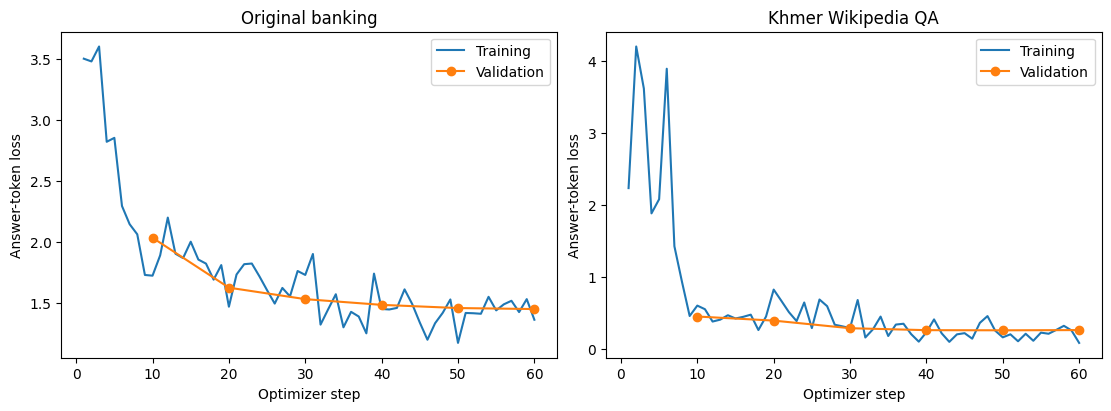

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
for ax, (name, result) in zip(axes, results.items(), strict=True):
    for key, label, marker in (("loss", "Training", None), ("eval_loss", "Validation", "o")):
        points = [(row["step"], row[key]) for row in result["loss_history"] if key in row]
        if points:
            steps, losses = zip(*points)
            ax.plot(steps, losses, label=label, marker=marker)
    ax.set(title=DATASETS[name], xlabel="Optimizer step", ylabel="Answer-token loss")
    ax.legend()
fig.savefig(RESULTS_DIR / "loss_comparison.png", dpi=160)
plt.show()

## 8. Results export

In [37]:
from importlib.metadata import version
from shutil import make_archive

metrics = {
    "model": MODEL_ID,
    "wandb_project": WANDB_PROJECT,
    "dataset_hashes": FILE_HASHES,
    "settings": {
        "seed": SEED,
        "steps": TRAINING_STEPS,
        "learning_rate": LEARNING_RATE,
        "lora_rank": LORA_RANK,
        "max_length": MAX_LENGTH,
        "batch_size": BATCH_SIZE,
        "gradient_accumulation_steps": ACCUMULATION_STEPS,
        "eval_steps": EVAL_STEPS,
        "generation": GENERATION_SETTINGS,
    },
    "packages": {name: version(name) for name in ("torch", "unsloth", "transformers", "trl", "wandb")},
    "gpu": torch.cuda.get_device_name(0),
    "results": results,
}
(RESULTS_DIR / "metrics.json").write_text(json.dumps(metrics, indent=2), encoding="utf-8")
(RESULTS_DIR / "DATASET_ATTRIBUTION.md").write_text(dataset_attribution, encoding="utf-8")
archive = make_archive("/content/TP03_Gemma3_results", "zip", root_dir=RESULTS_DIR)
files.download(archive)

## 9. Ask Gemma 3

In [38]:
from unsloth import FastModel
from unsloth.chat_templates import get_chat_template

import shutil
from pathlib import Path
from zipfile import ZipFile

import torch
from google.colab import files

CHAT_MAX_SEQUENCE_LENGTH = 2048
CHAT_MAX_ANSWER_TOKENS = 768
ADAPTER_WEIGHTS = ("adapter_config.json", "adapter_model.safetensors")

In [39]:
def extract_banking_adapter(archive, adapter_dir):
    prefix = "banking/adapter/"
    tokenizer_files = (
        "chat_template.jinja", "processor_config.json", "tokenizer.json",
        "tokenizer_config.json", "tokenizer.model", "special_tokens_map.json",
    )
    with ZipFile(archive) as bundle:
        members = set(bundle.namelist())
        if not all(prefix + name in members for name in ADAPTER_WEIGHTS):
            raise ValueError("The results ZIP does not contain the banking adapter.")

        adapter_dir.mkdir(parents=True, exist_ok=True)
        for name in (*tokenizer_files, *ADAPTER_WEIGHTS):
            if prefix + name in members:
                partial_file = adapter_dir / f"{name}.part"
                with bundle.open(prefix + name) as source, partial_file.open("wb") as target:
                    shutil.copyfileobj(source, target)
                partial_file.replace(adapter_dir / name)

In [40]:
def saved_banking_adapter():
    extracted = Path("/content/tp03_chat/adapter")
    results_dir = globals().get("RESULTS_DIR")
    candidates = [Path(results_dir) / "banking" / "adapter", extracted] if results_dir else [extracted]
    for candidate in candidates:
        if all((candidate / name).is_file() for name in ADAPTER_WEIGHTS):
            return candidate

    archive = Path("/content/TP03_Gemma3_results.zip")
    if not archive.is_file():
        uploads = files.upload()
        if archive.name not in uploads:
            raise ValueError(f"Expected {archive.name}.")
        archive.write_bytes(uploads[archive.name])
    extract_banking_adapter(archive, extracted)
    return extracted

In [41]:
@torch.inference_mode()
def answer_question(model, processor, prompt):
    tokenizer = getattr(processor, "tokenizer", processor)
    text = processor.apply_chat_template(
        [{"role": "user", "content": prompt}], tokenize=False, add_generation_prompt=True,
    )
    inputs = tokenizer(text, add_special_tokens=False, return_tensors="pt").to(model.device)
    prompt_length = inputs["input_ids"].shape[1]
    budget = min(CHAT_MAX_ANSWER_TOKENS, CHAT_MAX_SEQUENCE_LENGTH - prompt_length)
    if budget <= 0:
        raise ValueError("Shorten the passage or question so the model has room to answer.")
    stop_ids = sorted({tokenizer.eos_token_id, tokenizer.convert_tokens_to_ids("<end_of_turn>")}
                      - {None, tokenizer.unk_token_id})
    output = model.generate(
        **inputs, max_new_tokens=budget, do_sample=False, repetition_penalty=1.1,
        no_repeat_ngram_size=8, eos_token_id=stop_ids, pad_token_id=tokenizer.pad_token_id,
    )
    return tokenizer.decode(output[0, prompt_length:], skip_special_tokens=True).strip()

In [42]:
if not torch.cuda.is_available():
    raise RuntimeError("Select a Colab GPU runtime.")

adapter_dir = saved_banking_adapter()
if globals().get("loaded_chat_adapter") != adapter_dir:
    chat_model, chat_processor = FastModel.from_pretrained(
        model_name=str(adapter_dir), max_seq_length=CHAT_MAX_SEQUENCE_LENGTH, load_in_4bit=True,
    )
    chat_processor = get_chat_template(chat_processor, chat_template="gemma-3")
    FastModel.for_inference(chat_model)
    loaded_chat_adapter = adapter_dir

while True:
    question = input("Ask a question (Enter to stop): ").strip()
    if not question:
        break
    print(answer_question(chat_model, chat_processor, question))

Ask a question (Enter to stop): តើដូចម្តេចដែលហៅថា ឥណទានរថយន្ត?
ឥណទានរថយន្ដគឺជាប្រភេទឥណទានសម្រាប់ទិញរថយន្ដថ្មី ឬប្រើប្រាស់។ ឥណទាននេះអាចធ្វើឡើងបានតាមរយៈធនាគារផ្សេងៗ ឬសងខាងឯកត្តជន។ ម្ចាស់រថយន្ដនឹងត្រូវបង់ប្រាក់ដើម និងអត្រាកំណាត់ប្រាក់ទៅឲ្យធនាគារ ឬអ្នកផ្តល់ឥណទានជាប្រចាំតាមកំណត់។
Ask a question (Enter to stop): តើធនាគារ អេស៊ីលីដា​ ជាអ្វី?
ធនាគារ អេស៊ី លីដា គឺជាធនាគារឯកទេស ដែលមានមូលដ្ឋាននៅប្រទេស កម្ពុជា។ ធនាគារនេះ ផ្តល់សេវាកម្មជូនដល់អ្នកធ្វើដំណើរ និងអ្នកដែលធ្វើការងារនៅតាមរហ័ស ឬធ្វើការងារនៅតាមបណ្តាប្រទេសជិតខាង។ ធនាគារ អេស៊ី លីដា ត្រូវបានបង្កើតឡើងដោយក្រុមហ៊ុន អេស៊ីលីដា ភីអិលស៊ី។
Ask a question (Enter to stop): អ្វីទៅជា ធនាគារ អេស៊ីលីដា?
ធនាគារ អេស៊ី លីដា (អតិថិភាព អេស៊ី លីដា) គឺជាធនាគារឯកទេសមួយដែលផ្តល់សេវាកម្មធនាគារសម្រាប់បុគ្ការិន និងក្រុមគ្រួសាររបស់ក្រុមហ៊ុន អេស៊ី លីដា។ ធនាគារនេះមានទីតាំងនៅរាញ៉ូក និងបាត់តំប៉ឹង។
